# Sample Flight Analysis

This script defines a rocket's geometry (all SI base units), estimates it's aerodynamic performance from xFoil and RASAero II and then generates outputs (plots and printed tables).

These outputs can be saved by changing ```save=False``` to ```save=True``` within the script.

In [2]:
import faulthandler

_fault_log = open("kernel-fault.log", "a", buffering=1)
faulthandler.enable(file=_fault_log, all_threads=True)

print("Crash logging enabled")

# Install requirements (python modules) and import
try:
    from model.rocket import *
except ImportError:
    get_ipython().run_line_magic("pip", "install -r ./requirements.txt") # type: ignore
    from model.rocket import *

# hide warnings
import numpy as np
np.seterr("ignore")
import warnings
warnings.simplefilter("ignore")

from IPython.core.display import Image, display
from model.util.output.info import Table

Crash logging enabled


### Define rocket and environment

Selected: Cesaroni-M2020
Using cached RASAero aero data
Loaded aero data: c:\Users\rufus\OneDrive - The University of Manchester\Documents\University\Year 4\Advanced Research Project\System Model\data\rocket\Apis-Ascent\aeroData.csv


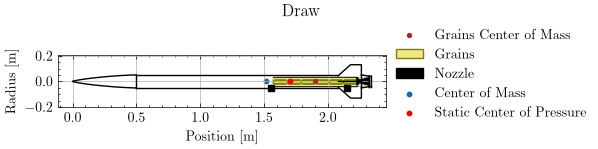

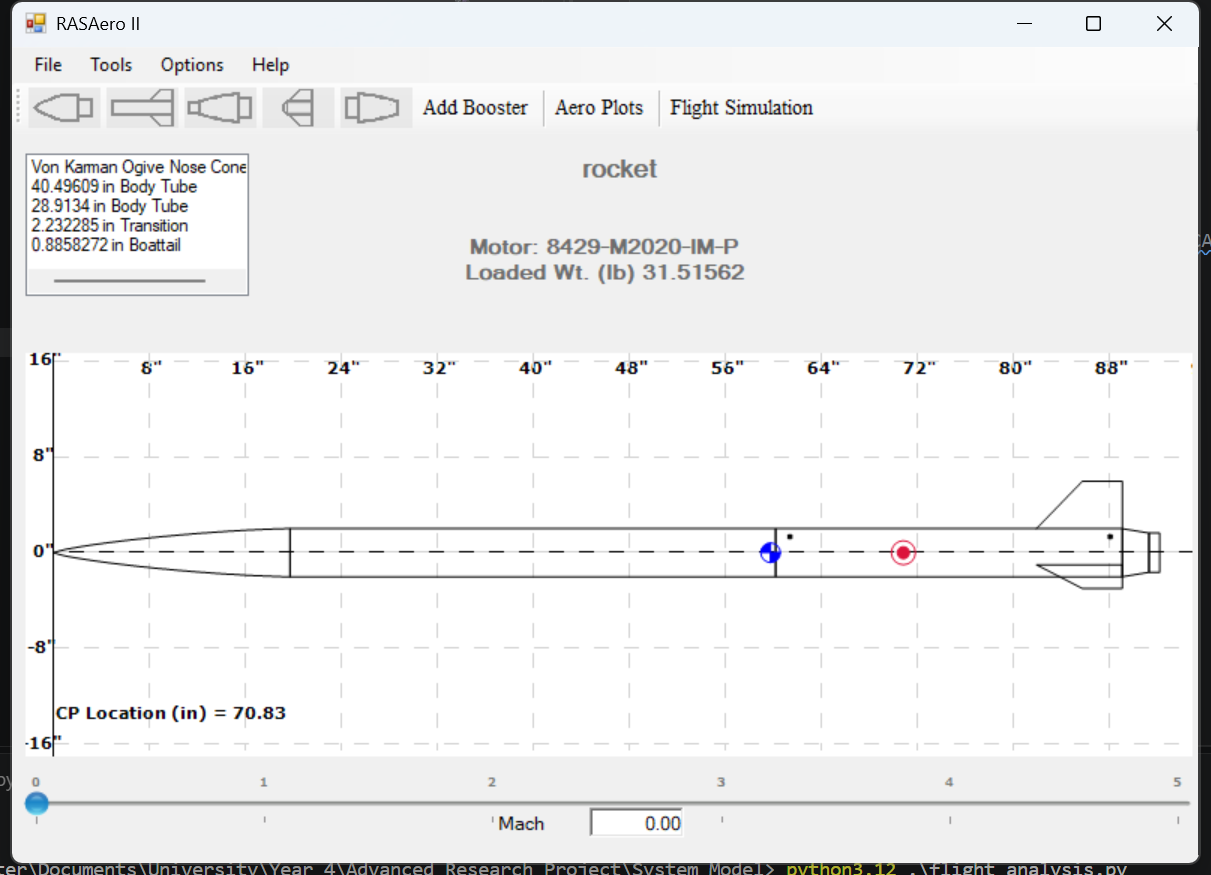

In [3]:
rocket = RocketGenerator(
    name="Apis-Ascent",
    diameter=102 / 1000,
    mass_without_motor=7261 / 1000,
    inertia_without_motor=(0.014508, 0.014508, 3.009982),
    center_of_mass_without_motor=1136 / 1000,
    aero="estimate"
)

rocket.add_rail_buttons(
    upper_button_position=1554 / 1000,
    lower_button_position=2153 / 1000,
    angular_position=60
)

rocket.add_nose(
    length=500 / 1000,
    kind="von karman",
    blunt_radius=3 / 1000
)

rocket.add_trapezoidal_fins(
    n=3,
    root_chord=182 / 1000,
    tip_chord=85 / 1000,
    span=100 / 1000,
    position=2081 / 1000,
    sweep_length=97 / 1000,
    airfoil_type="Subsonic NACA",
    leading_edge_radius=1 / 1000,
    thickness=6.8 / 1000
)

# tail
rocket.add_tail(
    top_diameter=102 / 1000,
    bottom_diameter=83 / 1000,
    length=56.7 / 1000,
    position=2263 / 1000,
)

# tail extension
rocket.add_tail(
    top_diameter=83 / 1000,
    bottom_diameter=82.9 / 1000,
    length=22.5 / 1000,
    position=2319.7 / 1000
)

rocket.add_parachute(
    name="Main Parachute",
    cd=2.2,
    diameter=1524 / 1000,
    trigger="altitude",
    deploy_altitude=300,
)

rocket.add_parachute(
    name="Drogue Parachute",
    cd=1.6,
    diameter=305 / 1000,
    trigger="apogee",
)

rocket.add_motor(
    motor_name="M2020",
    position=2325 / 1000
)

env = EnvironmentGenerator(
    latitude=0,
    longitude=0,
    elevation=0
)
env.set_atmospheric_model(
    wind_speed=5,
    wind_bearing=0
)

launcher = LauncherGenerator(
    length=6,
    heading=0,
    inclination=90
)

rasaero_config = RASAeroConfig(
    surface="Smooth (Zero Roughness)",
    turbulence_only_flight=False,
    use_modified_barrowman=True
)

flight = FlightGenerator(
    rocket=rocket,
    env=env,
    launcher=launcher,
    rasaero_config=rasaero_config
)

flight.ideal().rocket.plots.draw(show=True, save=False)
display(Image(filename=f"data/rocket/{flight.name}/rocket.png"))

### Simulate Flight and Outputs

Current Simulation Time: 227.1609 s
>>> Simulation Completed at Time: 223.6865 s
System Efficiency: 25.4 %
Apis-Ascent.flight-energies
                    Name  Energy [MJ]  % of Thrust
             Thrust Work         2.47       100.00
               Drag Work        -1.59       -64.20
            Gravity Work        -0.64       -25.95
   Other / Residual Work         0.24         9.81
   Apogee Kinetic Energy         0.00         0.05
Ideal Performance Energy        -0.63       -25.38
Apis-Ascent.flight-event-summary
                     Name  Time [s]  Altitude [km]  Velocity (Up) [m/s]  Acceleration (Up) [g]  Acceleration (+/- 1 s) (Up) [g]
             Launch Point      0.00           0.00                 0.00                   0.00                            19.05
              Out of Rail      0.27           0.01                42.78                  18.13                            19.19
            Motor Burnout      4.30           1.49               514.36                  -7

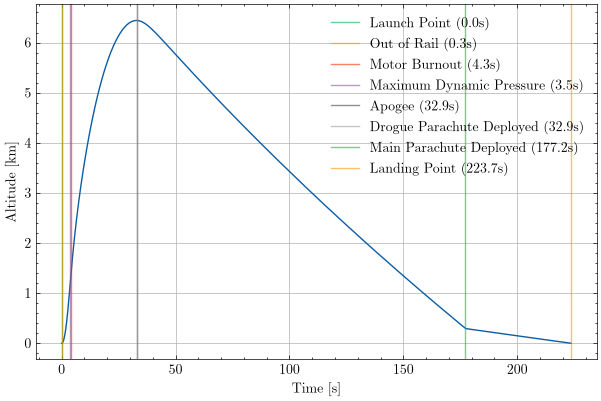

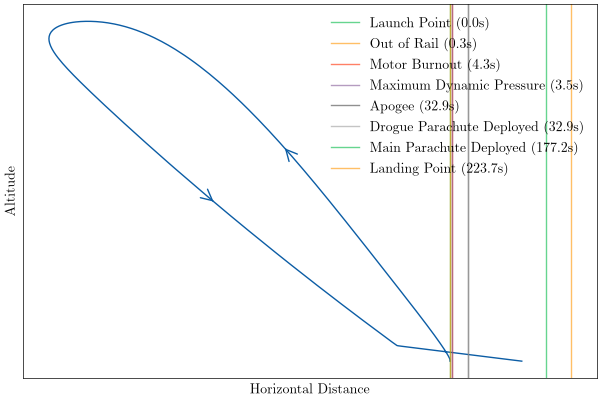

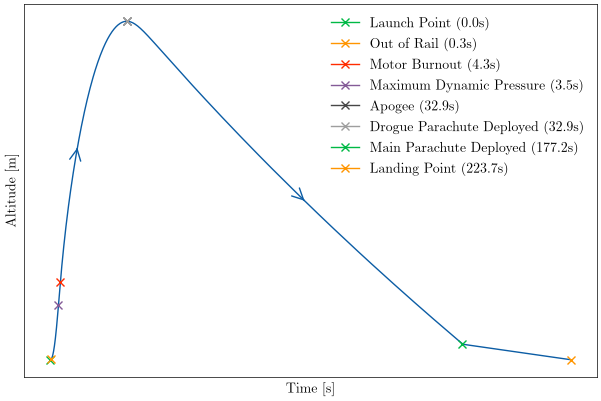

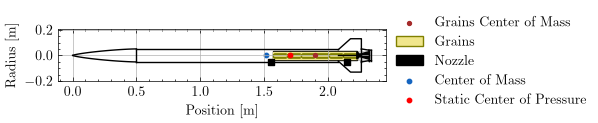

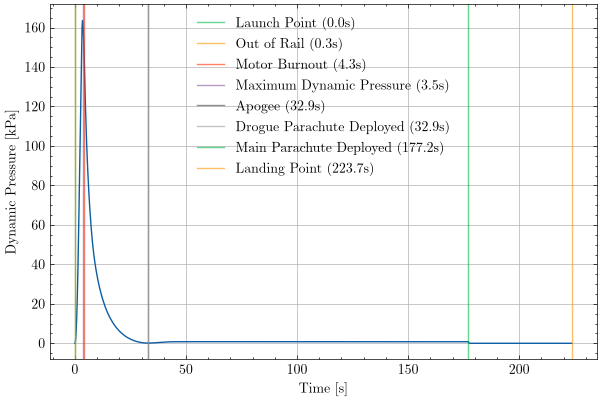

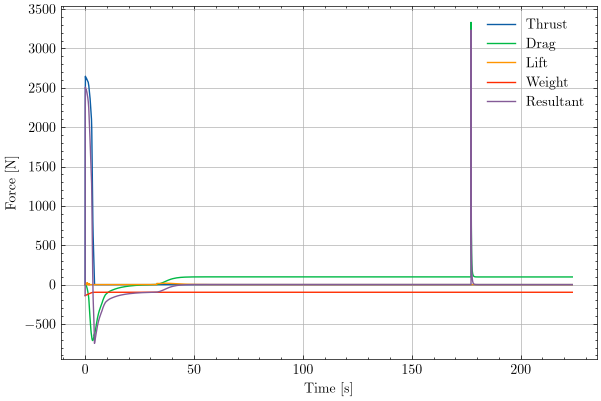

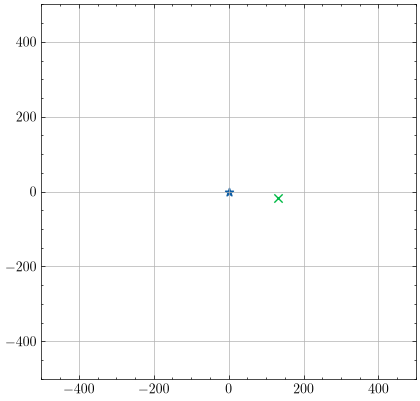

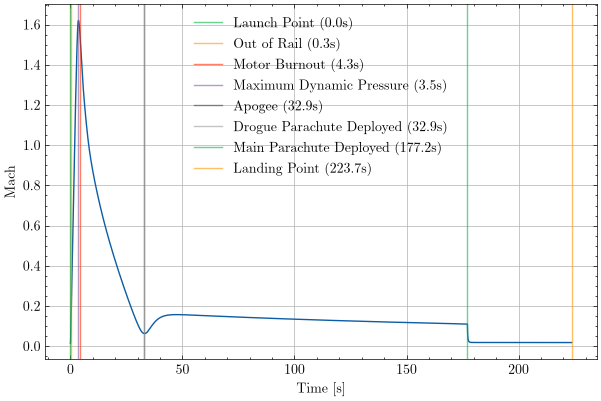

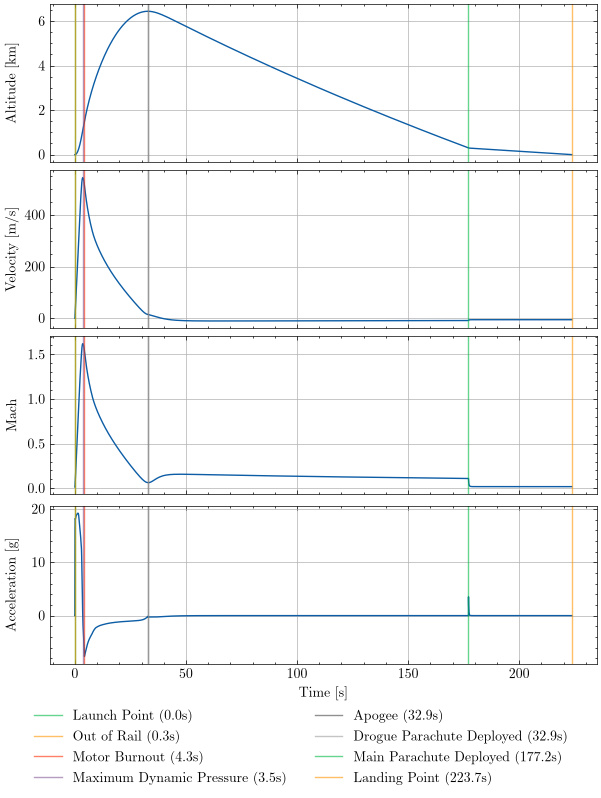

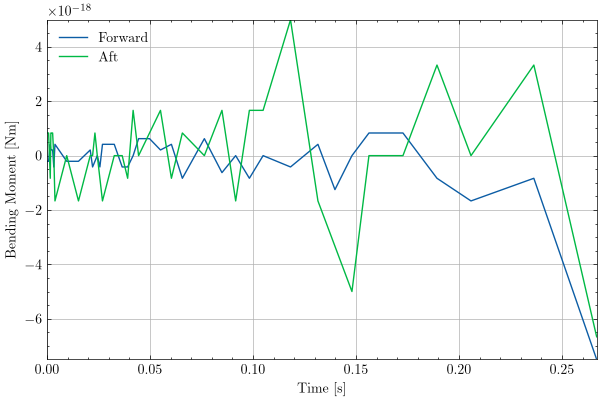

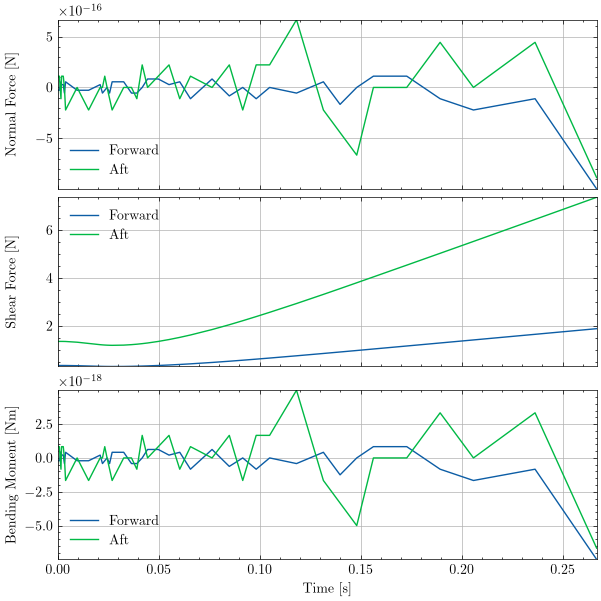

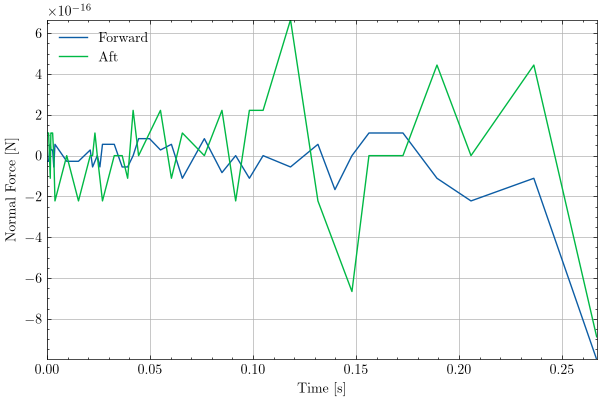

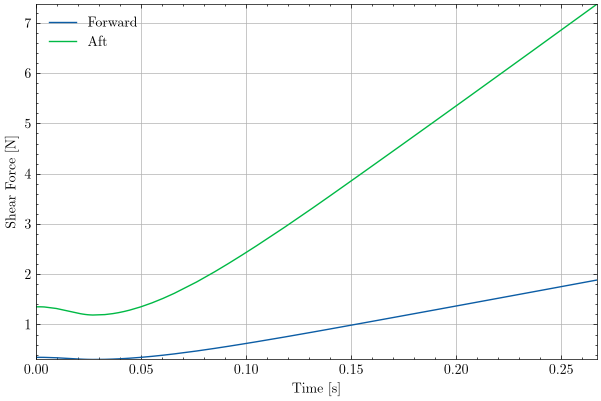

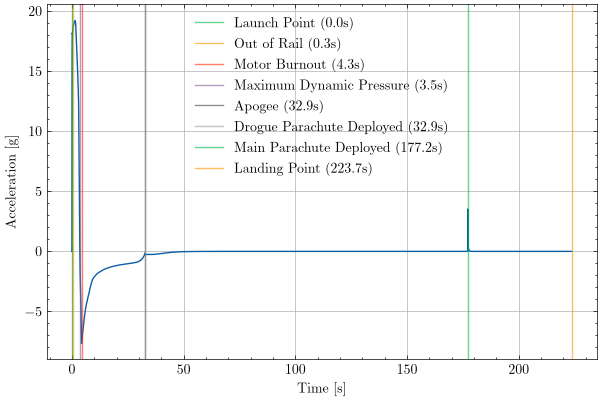

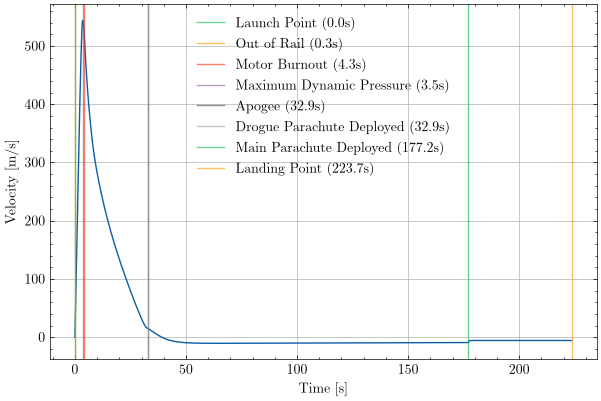

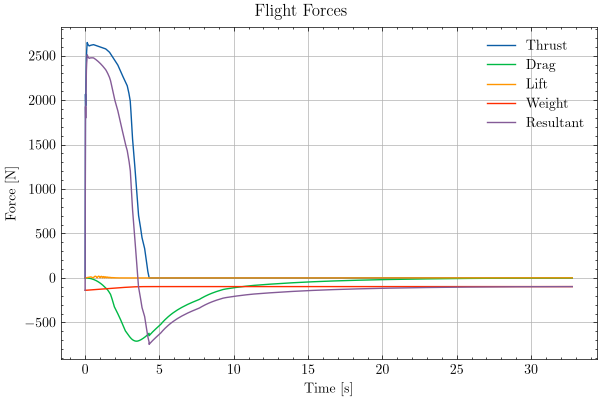

<Plots Apis-Ascent.flight-forces (ascent_only=True)>

In [4]:
flight = Flight(
    flight.ideal(),
    verbose=True
)

print(f"System Efficiency: {flight.system_efficiency():.1f} %")

flight.info.all(show=True, save=False)
flight.plots.all(show=True, save=False)
flight.plots.flight_forces(ascent_only=True, show=True, save=False)